**Sleep Disorder Prediction**
This project uses people's lifestyle and health data to predict whether someone has a sleep disorder, and which type.

**About the Dataset**
The Sleep Health and Lifestyle dataset has 400 rows and 13 columns about sleep habits and daily routines, including gender, age, occupation, sleep duration and quality, physical activity, stress level, BMI category, blood pressure, heart rate, daily steps, and whether a sleep disorder is present.

**Details about Sleep Disorder Column:**
- None: The individual does not exhibit any specific sleep disorder.
- Insomnia: The individual experiences difficulty falling asleep or staying asleep, leading to inadequate or poor-quality sleep.
- Sleep Apnea: The individual suffers from pauses in breathing during sleep, resulting in disrupted sleep patterns and potential health risks.

In [3]:
# importing the libraries needed

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
# load the dataset
df = pd.read_csv("/content/Sleep_health_and_lifestyle_dataset.csv")
df.head(10)

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
5,6,Male,28,Software Engineer,5.9,4,30,8,Obese,140/90,85,3000,Insomnia
6,7,Male,29,Teacher,6.3,6,40,7,Obese,140/90,82,3500,Insomnia
7,8,Male,29,Doctor,7.8,7,75,6,Normal,120/80,70,8000,NaN
8,9,Male,29,Doctor,7.8,7,75,6,Normal,120/80,70,8000,NaN
9,10,Male,29,Doctor,7.8,7,75,6,Normal,120/80,70,8000,NaN


## Data Preprocessing

In [5]:
# check for the data type
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


In [6]:
categories = ['Gender', 'Occupation', 'BMI Category']

In [7]:
# check for the missing value
df.isnull().sum()

,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


The null data on sleep disorder means the individual does not exhibit any specific sleep disorder -> impute with "None"

In [8]:
#replacing the null values with 'None' in the column 'Sleep Disorder'
df['Sleep Disorder'].fillna('None', inplace=True)

/tmp/ipykernel_3772/534262089.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Sleep Disorder'].fillna('None', inplace=True)


In [9]:
# drop unimportant features
df.drop('Person ID', axis = 1, inplace=True)

In [10]:
df.describe()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


In [11]:
# check the distributions of each categorical feature for the target (also checking the unique value)

for i in categories:
  print(df.groupby(i)['Sleep Disorder'].value_counts())
  print("\n")

Gender  Sleep Disorder
Female  None               82
        Sleep Apnea        67
        Insomnia           36
Male    None              137
        Insomnia           41
        Sleep Apnea        11
Name: count, dtype: int64


Occupation            Sleep Disorder
Accountant            None              30
                      Insomnia           7
Doctor                None              64
                      Sleep Apnea        4
                      Insomnia           3
Engineer              None              57
                      Insomnia           5
                      Sleep Apnea        1
Lawyer                None              42
                      Sleep Apnea        3
                      Insomnia           2
Manager               None               1
Nurse                 Sleep Apnea       61
                      None               9
                      Insomnia           3
Sales Representative  Sleep Apnea        2
Salesperson           Insomnia          29
 

- Instead of man, woman mostlikey to get insomnia and sleeap apnea.
- A nurse (Sleep Apnea), Salesperson (Imsonia), Teacher (Imsomnia)
- A person who is overweight mostlikeky to have a sleep dirsorder

## EDA

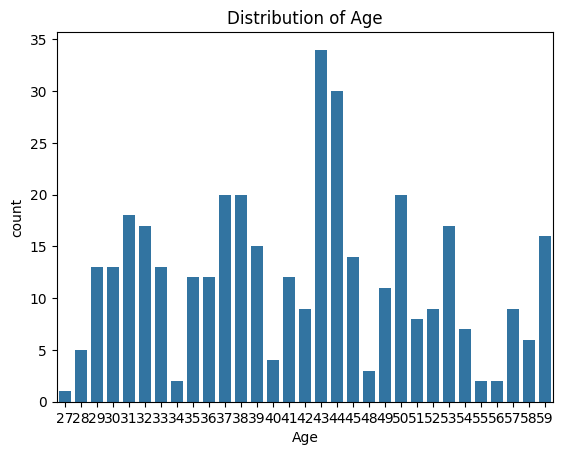

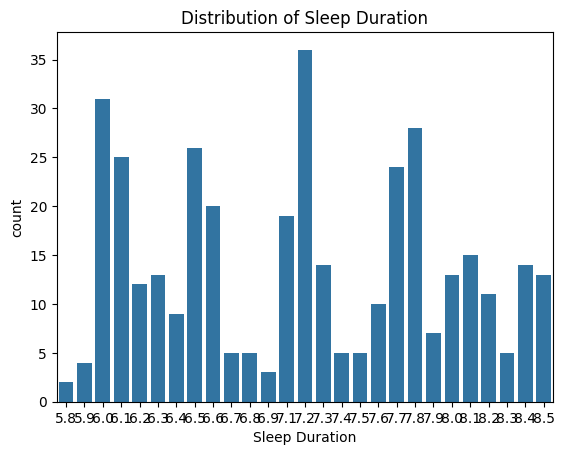

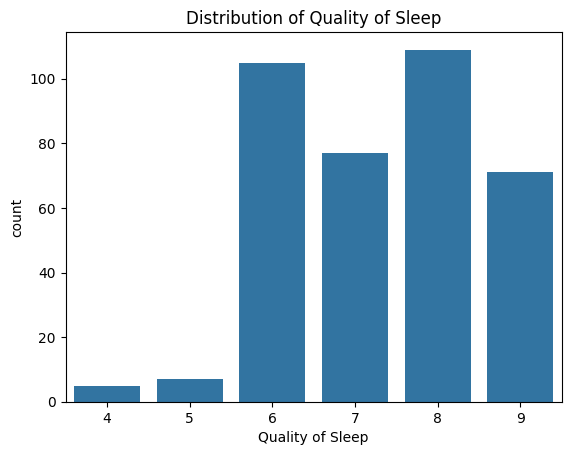

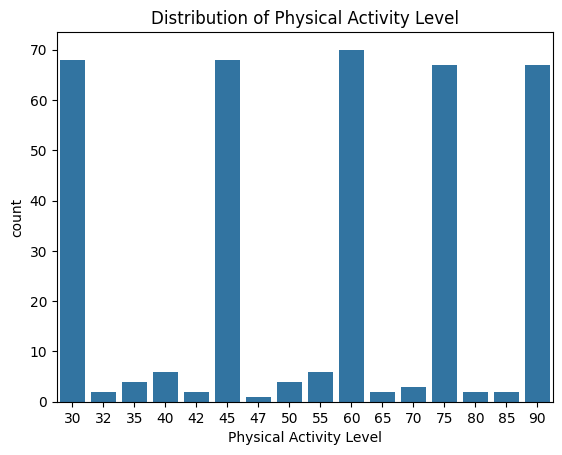

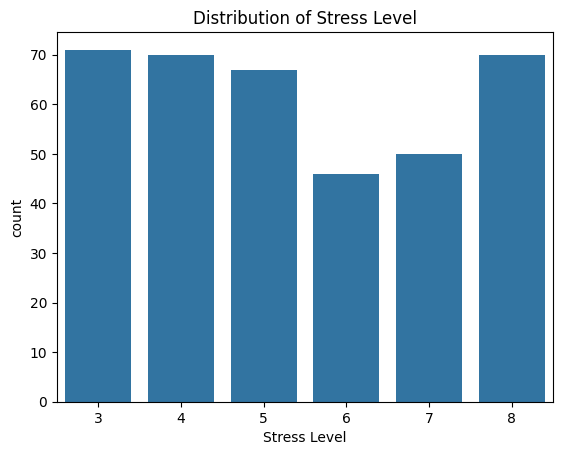

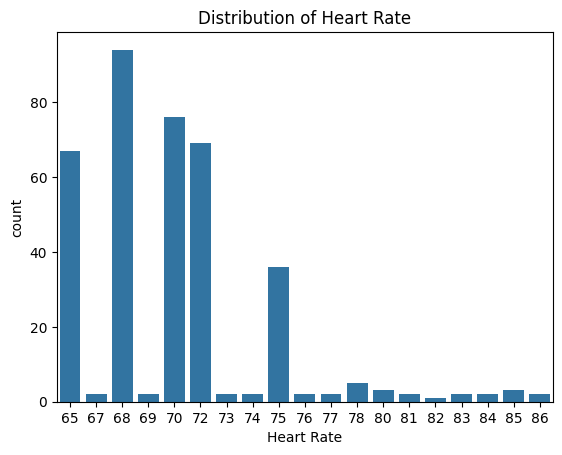

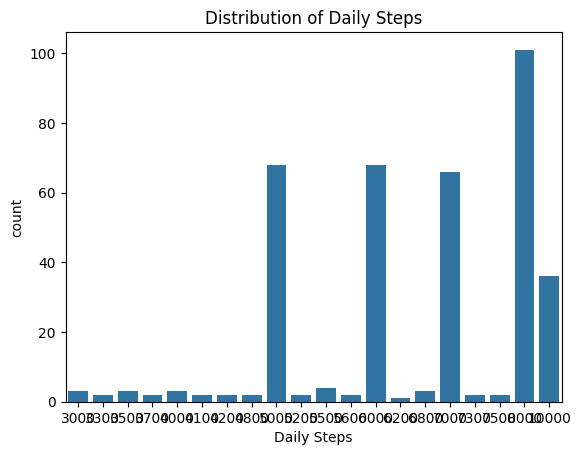

In [27]:
for i in ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps']:
  sns.countplot(x=i, data=df)
  plt.title(f"Distribution of {i}")
  plt.show()

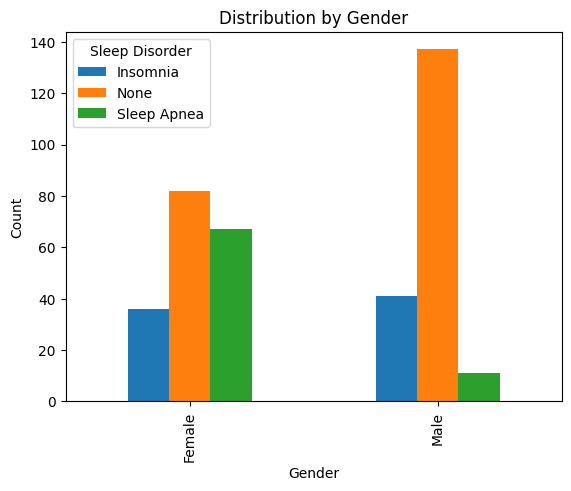

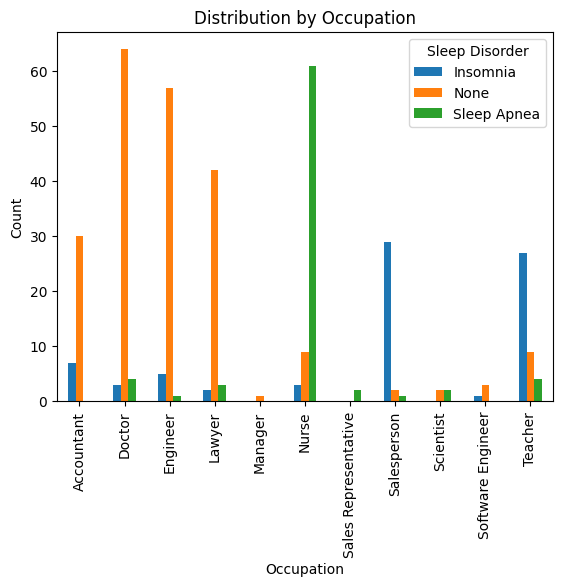

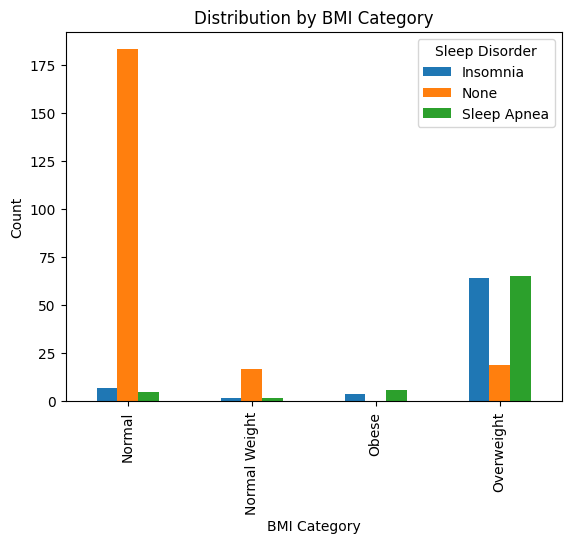

In [31]:
for i in categories:
    df.groupby(i)['Sleep Disorder'].value_counts().unstack().plot.bar()

    plt.title(f"Distribution by {i}")
    plt.ylabel("Count")
    plt.show()

- Occupation: Professions such as Doctor, Engineer, Lawyer, and Accountant mostly have no sleep disorder (None).   Nurse is heavily dominated by Sleep Apnea cases.   Salesperson and Teacher are dominated by Insomnia.   
- BMI Category: Individuals with Normal or Normal Weight BMI mostly do not suffer from any sleep disorder (None).   Those categorized as Overweight show a high prevalence of sleep disorders, accounting for almost all Insomnia and Sleep Apnea cases.   The Obese category has a small sample size, but all recorded individuals suffer from a sleep disorder (Insomnia or Sleep Apnea)
- Gender: Both genders are predominantly free of sleep disorders (None), though males have a higher proportion without disorders than females.   Sleep Apnea is significantly more common in Females.   Insomnia is relatively evenly distributed, with slightly more cases in Males.

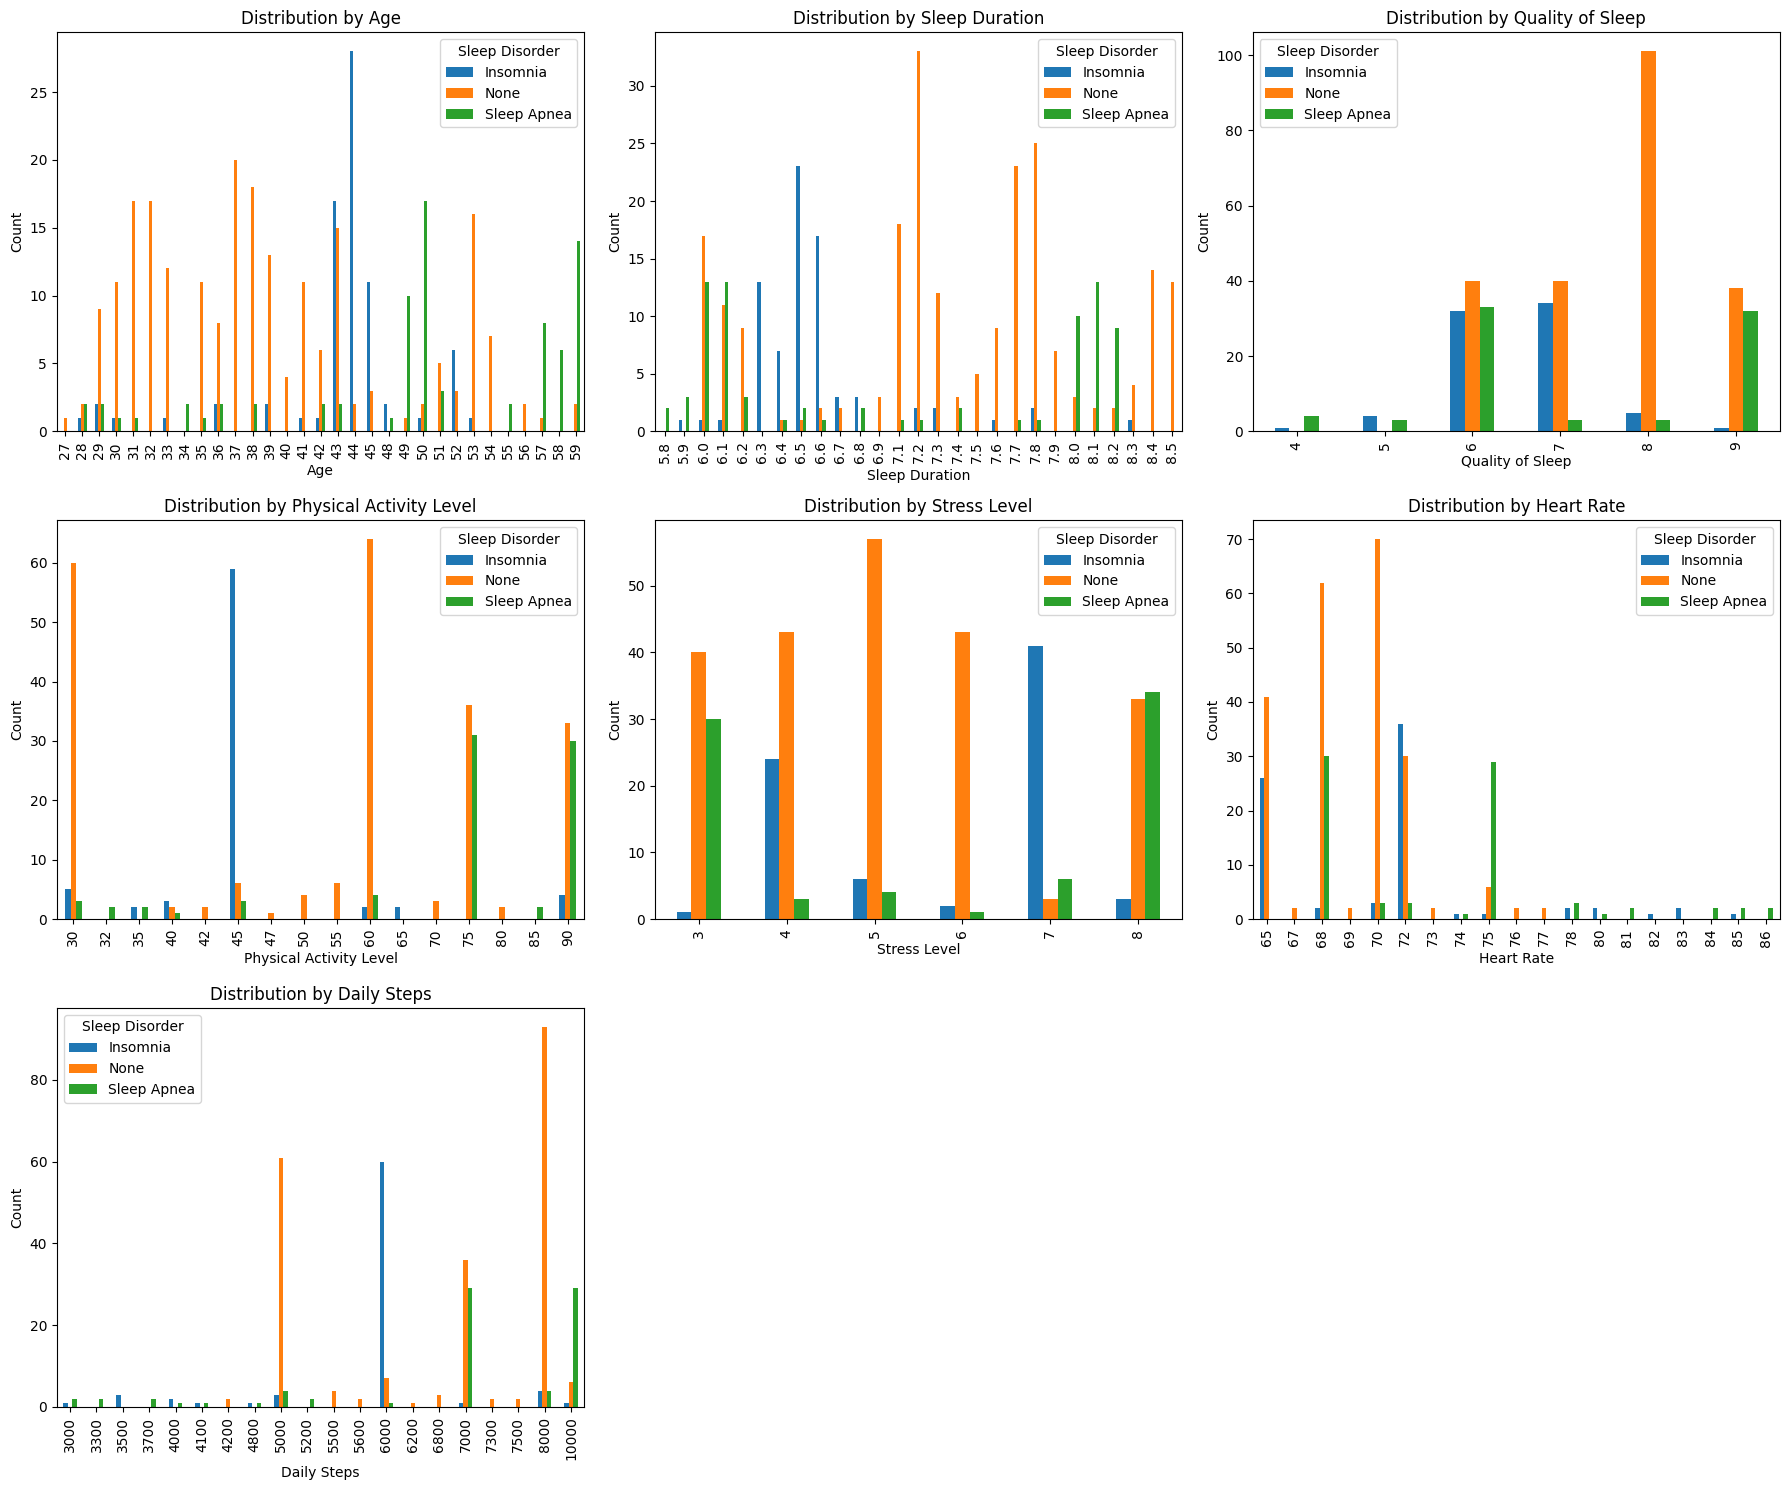

In [20]:
# features vs numerik
features = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps']
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for idx, i in enumerate(features):
    df.groupby(i)['Sleep Disorder'].value_counts().unstack().plot.bar(ax=axes[idx])
    axes[idx].set_title(f"Distribution by {i}")
    axes[idx].set_ylabel("Count")

# Hide any unused subplots
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

- Age: People without sleep disorders (None) are mostly younger to middle-aged (27–44 years old). Insomnia peaks around ages 43–45, while Sleep Apnea is most prominent among older individuals (57–59 years old).   
- Sleep Duration: Shorter sleep durations (5.9–6.6 hours) are predominantly seen in people with Insomnia. Moderate-to-longer sleep durations (7.1–8.5 hours) are dominated by those with no sleep disorders. Sleep Apnea spans across moderate and higher durations (such as 8.0–8.3 hours).   
- Quality of Sleep: High sleep quality (score of 8) is overwhelmingly represented by those without sleep disorders. Insomnia dominates moderate quality scores (scores 5–7), while Sleep Apnea is mostly present at scores 6 and 9.   
- Physical Activity Level: Moderate physical activity (level 45) consists mostly of individuals with Insomnia. Both Sleep Apnea patients and individuals without disorders show similar higher activity levels (levels 60, 75, and 90).   
- Stress Level: Lower stress levels (levels 3–5) are dominated by those without sleep disorders. Insomnia peaks at higher stress levels (levels 7–8), while Sleep Apnea is noticeably high at stress level 8.   
- Heart Rate: Lower to moderate heart rates (65–70 bpm) are mostly seen in individuals without sleep disorders. Insomnia spikes at 72 bpm, whereas Sleep Apnea shows a distinct spike at 75 bpm.  
-  Daily Steps: Higher step counts (8,000 and 10,000 steps) are dominated by the None and Sleep Apnea groups. Insomnia is heavily concentrated around moderate step counts (6,000 steps).

In [33]:
# correlation between each feature
df.select_dtypes("number").corr()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
Age,1.000000,0.344709,0.473734,0.178993,-0.422344,-0.225606,0.057973
Sleep Duration,0.344709,1.000000,0.883213,0.212360,-0.811023,-0.516455,-0.039533
Quality of Sleep,0.473734,0.883213,1.000000,0.192896,-0.898752,-0.659865,0.016791
Physical Activity Level,0.178993,0.212360,0.192896,1.000000,-0.034134,0.136971,0.772723
Stress Level,-0.422344,-0.811023,-0.898752,-0.034134,1.000000,0.670026,0.186829
Heart Rate,-0.225606,-0.516455,-0.659865,0.136971,0.670026,1.000000,-0.030309
Daily Steps,0.057973,-0.039533,0.016791,0.772723,0.186829,-0.030309,1.000000


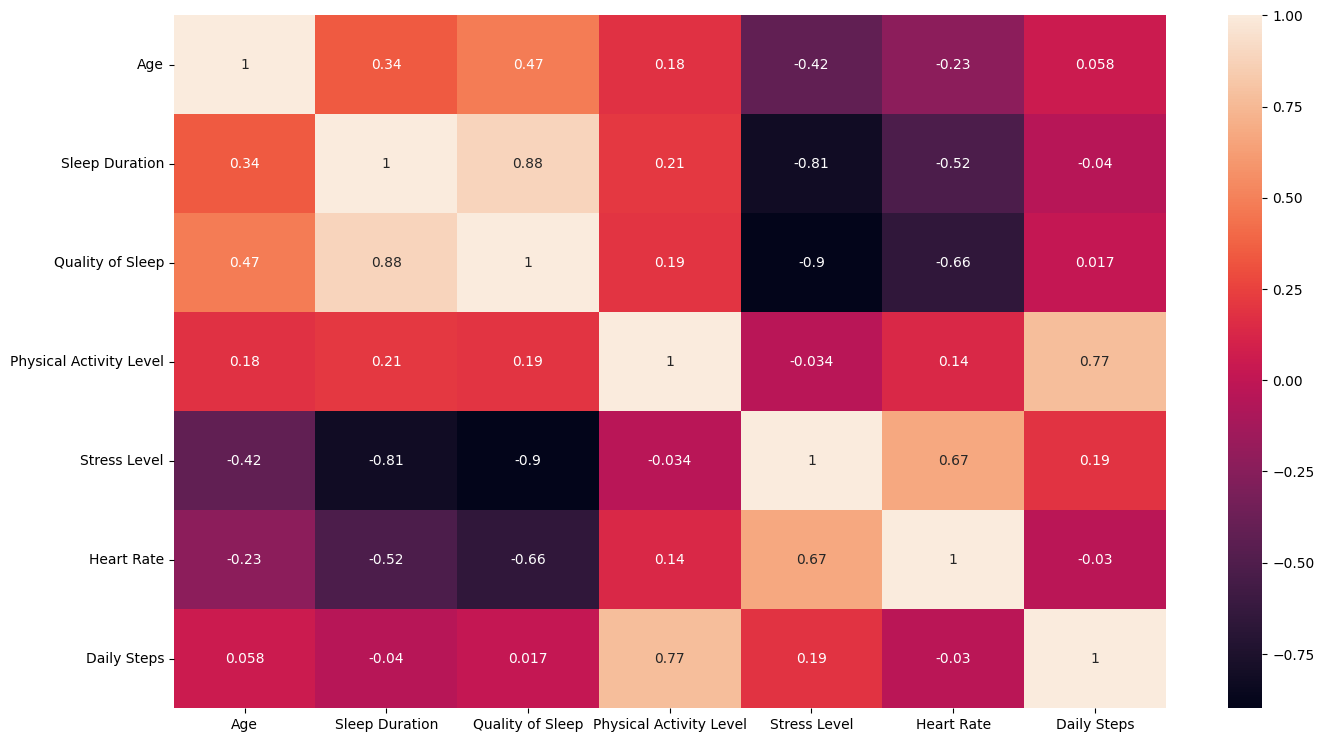

In [36]:
# correlation Matrix Heatmap
plt.figure(figsize=(16, 9))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

- Quality of Sleep vs. Sleep Duration (0.88): Strong positive correlation. Longer sleep duration significantly increases sleep quality.   
- Physical Activity Level vs. Daily Steps (0.77): Strong positive correlation. Higher physical activity level aligns directly with a higher daily step count.   
- Quality of Sleep vs. Stress Level (-0.90): Strong negative correlation. Higher stress levels severely reduce sleep quality.   
- Sleep Duration vs. Stress Level (-0.81): Strong negative correlation. Higher stress levels lead to shorter sleep duration.   
- Stress Level vs. Heart Rate (0.67): Moderate-to-strong positive correlation. Higher stress levels are associated with an increased heart rate.   
- Quality of Sleep vs. Heart Rate (-0.66): Moderate-to-strong negative correlation. Higher heart rates correspond to lower sleep quality.   
- Age correlations: Older age shows moderate positive correlation with better sleep quality (0.47) and sleep duration (0.34), as well as a moderate negative correlation with stress level (-0.42).

In [37]:
# check class balance
df["Sleep Disorder"].value_counts(normalize=True)

,proportion
Sleep Disorder,
None,0.585561
Sleep Apnea,0.208556
Insomnia,0.205882


## Modeling

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [39]:
df[['BP_Systolic', 'BP_Diastolic']] = df['Blood Pressure'].str.split('/', expand=True).astype(int)
df.drop('Blood Pressure', axis=1, inplace=True)
df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})

# split

X = df.drop('Sleep Disorder', axis=1)
y = df['Sleep Disorder']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [44]:
categorical_cols = ['Gender', 'Occupation', 'BMI Category']
numerical_cols = [col for col in X.columns if col not in categorical_cols]

num_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Pipeline for categorical featire
cat_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Merge preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, numerical_cols),
        ('cat', cat_transformer, categorical_cols)
    ]
)

#Pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42))
])


model_pipeline.fit(X_train, y_train)

y_pred = model_pipeline.predict(X_test)

## Evaluate

In [45]:
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy Score: 0.9333333333333333

Classification Report:
               precision    recall  f1-score   support

    Insomnia       0.78      0.93      0.85        15
        None       1.00      0.98      0.99        44
 Sleep Apnea       0.93      0.81      0.87        16

    accuracy                           0.93        75
   macro avg       0.90      0.91      0.90        75
weighted avg       0.94      0.93      0.93        75



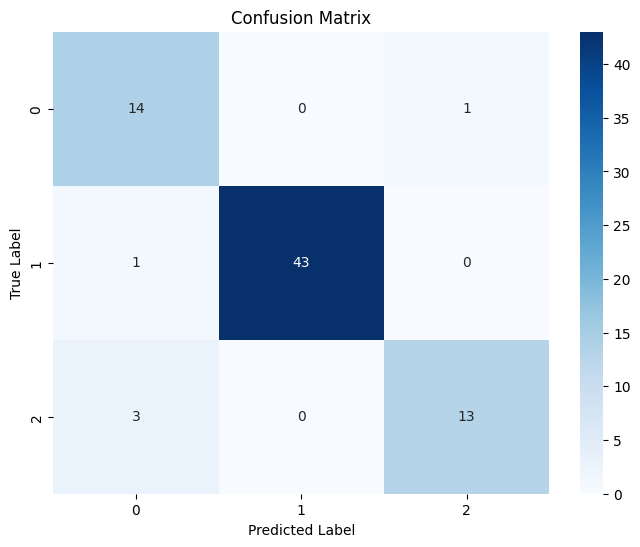

In [46]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

Applying techniques to address class imbalance successfully boosted sensitivity (recall) for Insomnia to 93%, making the model more conservative toward detecting insomnia cases. The control group (None) maintains perfect precision (1.00) and near-perfect recall (0.98), confirming that the model reliably distinguishes healthy individuals from those with sleep disorders without false positives. The overall macro F1-score stands at 0.90 and weighted F1-score at 0.93, demonstrating a balanced trade-off depending on whether higher recall for Insomnia or higher recall for Sleep Apnea is prioritized for diagnostic screening.   

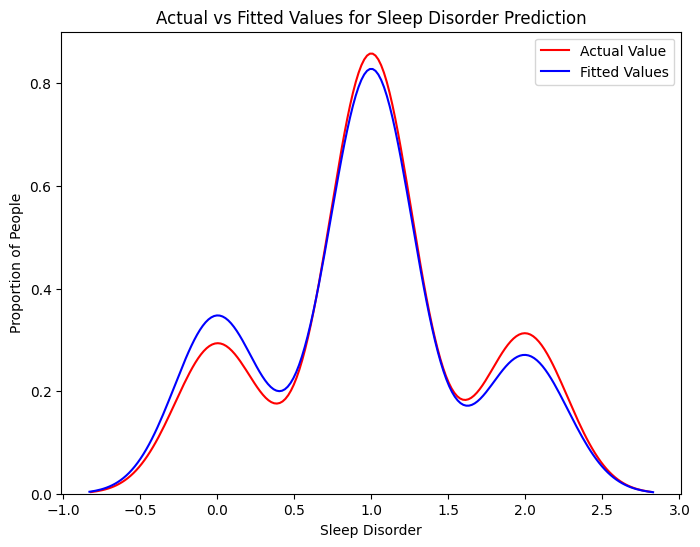

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_test_num = le.fit_transform(y_test)
y_pred_num = le.transform(y_pred)

plt.figure(figsize=(8, 6))

sns.kdeplot(y_test_num, color="r", label="Actual Value")
sns.kdeplot(y_pred_num, color="b", label="Fitted Values")

plt.title('Actual vs Fitted Values for Sleep Disorder Prediction')
plt.xlabel('Sleep Disorder')
plt.ylabel('Proportion of People')
plt.legend()

plt.show()

In [52]:
# check overfit/underfit
from sklearn.model_selection import cross_val_score

train_score = model_pipeline.score(X_train, y_train)
val_score = cross_val_score(model_pipeline, X_train, y_train, cv=5).mean()

print(f"Train: {train_score:.2f}")
print(f"Validation: {val_score:.2f}")

Train: 0.93
Validation: 0.86
